In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob

PHASE2   = '/content/drive/MyDrive/FinalYearProject-Phase2'
BASE     = '/content/drive/MyDrive/Final Year Project'   # old folder, only checked for the pretrained .pth
LOCAL    = '/content/step5_data'                         # fast local copy (Drive I/O is slow)
OUT      = f'{PHASE2}/level5_results'                    # all outputs are saved here
CKPT_DIR = f'{OUT}/checkpoints'
FIG_DIR  = f'{OUT}/figures'
REST_DIR = f'{OUT}/restored'

assert os.path.exists(PHASE2), f'Folder not found: {PHASE2}'

# Find the zip or the step5 folder wherever it sits inside PHASE2
zips = glob.glob(f'{PHASE2}/**/HDC2021_step5.zip', recursive=True)
if len(zips) > 0:
    ZIP_PATH = zips[0]
else:
    ZIP_PATH = f'{PHASE2}/HDC2021_step5.zip'

dirs = [d for d in glob.glob(f'{PHASE2}/**/step5', recursive=True) if os.path.isdir(d) and 'level5_results' not in d]
if len(dirs) > 0:
    DRIVE_DIR = dirs[0]
else:
    DRIVE_DIR = f'{PHASE2}/step5'

for d in [LOCAL, OUT, CKPT_DIR, FIG_DIR, REST_DIR]:
    os.makedirs(d, exist_ok=True)

print('Contents of PHASE2:', os.listdir(PHASE2))
print('Zip found   :', os.path.exists(ZIP_PATH), '->', ZIP_PATH)
print('Folder found:', os.path.exists(DRIVE_DIR), '->', DRIVE_DIR)
print('Outputs ->', OUT)

Mounted at /content/drive
Contents of PHASE2: ['single_image_defocus_deblurring.pth', 'HDC2021_step5.zip', 'level5_results']
Zip found   : True -> /content/drive/MyDrive/FinalYearProject-Phase2/HDC2021_step5.zip
Folder found: False -> /content/drive/MyDrive/FinalYearProject-Phase2/step5
Outputs -> /content/drive/MyDrive/FinalYearProject-Phase2/level5_results


In [ ]:
!pip install -q einops tifffile scikit-image easyocr rapidfuzz

import re, json, glob, random, shutil, time
import numpy as np
import pandas as pd
import cv2, tifffile
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from rapidfuzz.distance import Levenshtein

assert torch.cuda.is_available(), 'No GPU - Runtime > Change runtime type > T4 GPU'
DEVICE = 'cuda'
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('PyTorch:', torch.__version__)
print('GPU    :', torch.cuda.get_device_name(0))
print('VRAM   :', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), 'GB')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 97.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 116.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 31.7 MB/s eta 0:00:00
PyTorch: 2.11.0+cu130
GPU    : Tesla T4
VRAM   : 15.6 GB


In [ ]:
already = [d for d in glob.glob(f'{LOCAL}/**/CAM01', recursive=True) if '__MACOSX' not in d]

if len(already) > 0:
    print('Already extracted:', already)
elif os.path.exists(ZIP_PATH):
    print('Copying zip from Drive (2.5 GB, ~2-4 min)...')
    shutil.copy(ZIP_PATH, '/content/step5.zip')
    print('Unzipping...')
    !unzip -q -o "/content/step5.zip" -d "{LOCAL}"
    os.remove('/content/step5.zip')
elif os.path.exists(DRIVE_DIR):
    print('Copying folder from Drive...')
    shutil.copytree(DRIVE_DIR, f'{LOCAL}/step5', dirs_exist_ok=True)
else:
    raise FileNotFoundError(f'Upload HDC2021_step5.zip to {PHASE2}')

for d in sorted(glob.glob(f'{LOCAL}/**/CAM0*', recursive=True)):
    if '__MACOSX' not in d:
        print(d, '->', len(glob.glob(d + '/*sample_*.tif')), 'images')

Copying zip from Drive (2.5 GB, ~2-4 min)...
Unzipping...
/content/step5_data/step5/Times/CAM01 -> 100 images
/content/step5_data/step5/Times/CAM02 -> 100 images
/content/step5_data/step5/Verdana/CAM01 -> 100 images
/content/step5_data/step5/Verdana/CAM02 -> 100 images


Total pairs: 200
timesR        100
verdanaRef    100
Edge energy  CAM01 (GT): 0.000512   CAM02 (input): 0.000007


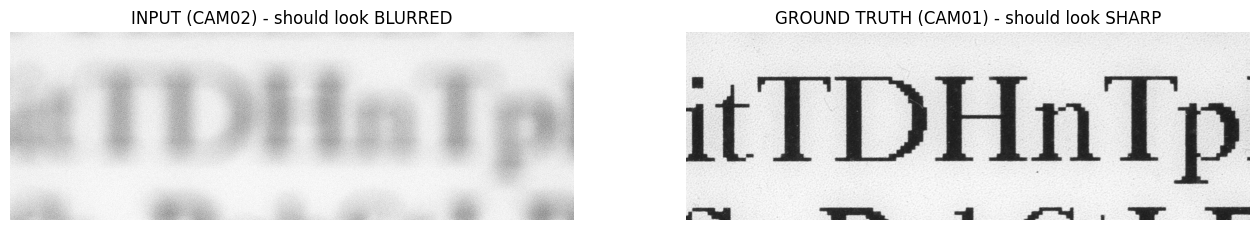

In [ ]:
SAMPLE_RE = re.compile(r'^focusStep_5_(timesR|verdanaRef)_size_30_sample_(\d{4})\.tif$')

def read_raw(path):
    img = tifffile.imread(path).astype(np.float32)
    if img.ndim == 3:
        img = img.mean(axis=-1)
    return img

def normalise(img):
    bg = np.percentile(img, 99.5)
    if bg <= 0:
        bg = img.max() + 1e-6
    return np.clip(img / bg, 0.0, 1.0)

pairs = []
for root, dirs, files in os.walk(LOCAL):
    if '__MACOSX' in root:
        continue
    if os.path.basename(root) != 'CAM01':
        continue
    cam2_dir = os.path.join(os.path.dirname(root), 'CAM02')
    cam1_set = set(f for f in files if SAMPLE_RE.match(f))
    cam2_set = set(f for f in os.listdir(cam2_dir) if SAMPLE_RE.match(f))
    if cam1_set != cam2_set:
        print('WARNING filename mismatch in', root)
    for f in sorted(cam1_set & cam2_set):
        m = SAMPLE_RE.match(f)
        pairs.append({
            'id':     f'{m.group(1)}_{m.group(2)}',
            'font':   m.group(1),
            'sample': int(m.group(2)),
            'cam01':  os.path.join(root, f),
            'cam02':  os.path.join(cam2_dir, f),
            'txt':    os.path.join(root, f.replace('.tif', '.txt')),
        })
print('Total pairs:', len(pairs))
print(pd.Series([p['font'] for p in pairs]).value_counts().to_string())

# HDC 2021 convention: CAM01 = focused (ground truth), CAM02 = defocused (input)
SHARP_KEY, BLUR_KEY = 'cam01', 'cam02'

def edge_energy(img):
    # Smooth first so sensor noise is NOT counted as sharpness
    sm = cv2.GaussianBlur(img, (0, 0), 2.0)
    gy, gx = np.gradient(sm)
    return float(np.mean(gx ** 2 + gy ** 2))

e_sharp, e_blur = [], []
for p in random.sample(pairs, 10):
    e_sharp.append(edge_energy(normalise(read_raw(p[SHARP_KEY]))))
    e_blur.append(edge_energy(normalise(read_raw(p[BLUR_KEY]))))
print(f'Edge energy  {SHARP_KEY.upper()} (GT): {np.mean(e_sharp):.6f}   {BLUR_KEY.upper()} (input): {np.mean(e_blur):.6f}')
assert np.mean(e_sharp) > np.mean(e_blur), 'GT camera is not sharper than input camera - STOP and check'

# Visual confirmation
p = pairs[0]
s = normalise(read_raw(p[SHARP_KEY]))
b = normalise(read_raw(p[BLUR_KEY]))
H, W = s.shape
fig, ax = plt.subplots(1, 2, figsize=(16, 3))
ax[0].imshow(b[H // 2 - 200:H // 2 + 200, W // 2 - 600:W // 2 + 600], cmap='gray', vmin=0, vmax=1)
ax[0].set_title(f'INPUT ({BLUR_KEY.upper()}) - should look BLURRED')
ax[1].imshow(s[H // 2 - 200:H // 2 + 200, W // 2 - 600:W // 2 + 600], cmap='gray', vmin=0, vmax=1)
ax[1].set_title(f'GROUND TRUTH ({SHARP_KEY.upper()}) - should look SHARP')
for a in ax:
    a.axis('off')
plt.show()

In [ ]:
SPLIT_FILE = f'{OUT}/split.json'

if os.path.exists(SPLIT_FILE):
    split = json.load(open(SPLIT_FILE))
    print('Loaded existing split')
else:
    rng = random.Random(SEED)
    split = {'train': [], 'val': [], 'test': []}
    for font in ['timesR', 'verdanaRef']:
        ids = sorted(p['id'] for p in pairs if p['font'] == font)
        rng.shuffle(ids)
        split['test']  += ids[:20]    # 20 test per font  -> 40
        split['val']   += ids[20:25]  # 5 val per font    -> 10 (checkpoint selection)
        split['train'] += ids[25:]    # 75 train per font -> 150
    json.dump(split, open(SPLIT_FILE, 'w'), indent=2)

tr, va, te = set(split['train']), set(split['val']), set(split['test'])
assert len(tr & va) == 0 and len(tr & te) == 0 and len(va & te) == 0, 'LEAKAGE'
print(f"Train {len(tr)} | Val {len(va)} | Test {len(te)} | disjoint: True")

Loaded existing split
Train 150 | Val 10 | Test 40 | disjoint: True


In [ ]:
MARGIN = 48   # pixels trimmed from every border after warping

def blur_for_matching(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigma)

def estimate_blur_sigma(s, b):
    H, W = s.shape
    cy, cx = H // 2, W // 2
    R = 60
    region = b[cy - 300 - R:cy + 300 + R, cx - 800 - R:cx + 800 + R]
    best_sig, best_ncc = 0, -1.0
    for sig in [5, 10, 15, 20, 25, 30, 35, 40]:
        tmpl = blur_for_matching(s, sig)[cy - 300:cy + 300, cx - 800:cx + 800]
        ncc = cv2.matchTemplate(region, tmpl, cv2.TM_CCOEFF_NORMED).max()
        if ncc > best_ncc:
            best_sig, best_ncc = sig, ncc
    return best_sig

def match_points(s, b, sigma, ph=160, pw=320, R=60, step=80):
    sb = blur_for_matching(s, sigma)
    H, W = s.shape
    src, dst = [], []
    for y in range(R + ph // 2, H - R - ph // 2, step):
        for x in range(R + pw // 2, W - R - pw // 2, step):
            if s[y - ph // 2:y + ph // 2, x - pw // 2:x + pw // 2].std() < 0.08:
                continue
            tmpl = sb[y - ph // 2:y + ph // 2, x - pw // 2:x + pw // 2]
            region = b[y - ph // 2 - R:y + ph // 2 + R, x - pw // 2 - R:x + pw // 2 + R]
            r = cv2.matchTemplate(region, tmpl, cv2.TM_CCOEFF_NORMED)
            _, mx, _, loc = cv2.minMaxLoc(r)
            if mx < 0.8:
                continue
            src.append((x, y))
            dst.append((x + loc[0] - R, y + loc[1] - R))
    return np.float32(src), np.float32(dst)

def warp_gt(s, M):
    H, W = s.shape
    return cv2.warpAffine(s, M, (W, H), flags=cv2.INTER_CUBIC | cv2.WARP_INVERSE_MAP, borderMode=cv2.BORDER_REPLICATE)

def align_score(s, b, sigma):
    # correlation between blurred GT and real input over the text area (higher = better aligned)
    sb = blur_for_matching(s, sigma)
    m = cv2.dilate((cv2.GaussianBlur(b, (0, 0), 5) < 0.9).astype(np.uint8), np.ones((61, 61), np.uint8)) > 0
    m[:80] = False
    m[-80:] = False
    m[:, :80] = False
    m[:, -80:] = False
    return float(np.corrcoef(sb[m], b[m])[0, 1])

# 1) Load and normalise everything
raw = {}
gt_text = {}
for p in tqdm(pairs, desc='Loading'):
    s = normalise(read_raw(p[SHARP_KEY]))
    b = normalise(read_raw(p[BLUR_KEY]))
    assert s.shape == b.shape, p['id']
    raw[p['id']] = (b, s)
    if os.path.exists(p['txt']):
        gt_text[p['id']] = open(p['txt'], encoding='utf-8', errors='ignore').read()
    else:
        gt_text[p['id']] = ''

# 2) Fit ONE global affine (camera geometry is fixed) using TRAINING images only
fit_ids = random.Random(SEED).sample(split['train'], min(12, len(split['train'])))
BLUR_SIGMA = int(np.median([estimate_blur_sigma(raw[i][1], raw[i][0]) for i in fit_ids[:4]]))
all_src, all_dst = [], []
for i in tqdm(fit_ids, desc='Matching'):
    src, dst = match_points(raw[i][1], raw[i][0], BLUR_SIGMA)
    all_src.append(src)
    all_dst.append(dst)
all_src = np.concatenate(all_src)
all_dst = np.concatenate(all_dst)
# M maps INPUT pixel coords -> GT pixel coords (used with WARP_INVERSE_MAP)
M, inl = cv2.estimateAffine2D(all_dst, all_src, ransacReprojThreshold=3.0, maxIters=5000)
print(f'Blur sigma ~{BLUR_SIGMA}px | {len(all_src)} matched patches | {int(inl.sum())} RANSAC inliers')
print('Affine (input -> GT):\n', np.round(M, 4))
np.save(f'{OUT}/registration_affine.npy', M)

# 3) Warp every GT into the input frame, trim borders, check alignment on every pair
data, checks = {}, []
for pid in tqdm(raw, desc='Registering'):
    b, s = raw[pid]
    w = np.clip(warp_gt(s, M), 0, 1)
    before = align_score(s, b, BLUR_SIGMA)
    after = align_score(w, b, BLUR_SIGMA)
    b_c = b[MARGIN:-MARGIN, MARGIN:-MARGIN]
    w_c = w[MARGIN:-MARGIN, MARGIN:-MARGIN]
    data[pid] = (b_c.astype(np.float16), w_c.astype(np.float16))
    checks.append({'id': pid, 'ncc_before': before, 'ncc_after': after})
del raw

chk = pd.DataFrame(checks)
chk.to_csv(f'{OUT}/pairing_checks.csv', index=False)
print(f"Alignment NCC  before: mean {chk.ncc_before.mean():.3f} | after: mean {chk.ncc_after.mean():.3f}, min {chk.ncc_after.min():.3f}")
print('Pairs with NCC_after < 0.7 (check these):', chk[chk.ncc_after < 0.7].id.tolist())
print('Image size after trim:', data[pairs[0]['id']][0].shape)
print(f'RAM used by images: {sum(v[0].nbytes + v[1].nbytes for v in data.values()) / 1e9:.2f} GB')

Loading:   0%|          | 0/200 [00:00<?, ?it/s]

Matching:   0%|          | 0/12 [00:00<?, ?it/s]

Blur sigma ~25px | 2950 matched patches | 1581 RANSAC inliers
Affine (input -> GT):
 [[ 1.0295e+00 -4.0000e-04 -3.2080e+01]
 [-5.2000e-03  1.0245e+00  3.6730e-01]]


Registering:   0%|          | 0/200 [00:00<?, ?it/s]

Alignment NCC  before: mean 0.792 | after: mean 0.892, min 0.878
Pairs with NCC_after < 0.7 (check these): []
Image size after trim: (1364, 2264)
RAM used by images: 2.47 GB


In [ ]:
import importlib.util

RESTORMER_DIR = '/content/Restormer'
if not os.path.exists(RESTORMER_DIR):
    !git clone -q https://github.com/swz30/Restormer.git {RESTORMER_DIR}

# Load only the architecture file (avoids basicsr import problems)
spec = importlib.util.spec_from_file_location('restormer_arch', f'{RESTORMER_DIR}/basicsr/models/archs/restormer_arch.py')
arch = importlib.util.module_from_spec(spec)
spec.loader.exec_module(arch)

WEIGHT_CANDIDATES = [
    f'{PHASE2}/single_image_defocus_deblurring.pth',
    f'{BASE}/Restormer/Defocus_Deblurring/pretrained_models/single_image_defocus_deblurring.pth',
]
PRETRAINED = None
for c in WEIGHT_CANDIDATES:
    if os.path.exists(c):
        PRETRAINED = c
        break
if PRETRAINED is None:
    PRETRAINED = WEIGHT_CANDIDATES[0]
    !wget -q -O "{PRETRAINED}" https://github.com/swz30/Restormer/releases/download/v1.0/single_image_defocus_deblurring.pth
print('Pretrained weights:', PRETRAINED, '|', round(os.path.getsize(PRETRAINED) / 1e6, 1), 'MB')

def build_model(weights=PRETRAINED):
    m = arch.Restormer(inp_channels=3, out_channels=3, dim=48, num_blocks=[4, 6, 6, 8],
                       num_refinement_blocks=4, heads=[1, 2, 4, 8], ffn_expansion_factor=2.66,
                       bias=False, LayerNorm_type='WithBias', dual_pixel_task=False)
    ck = torch.load(weights, map_location='cpu')
    if 'params' in ck:
        ck = ck['params']
    m.load_state_dict(ck, strict=True)
    return m.to(DEVICE)

_m = build_model()
print('Total params:', round(sum(p.numel() for p in _m.parameters()) / 1e6, 2), 'M')
del _m
torch.cuda.empty_cache()

Pretrained weights: /content/drive/MyDrive/FinalYearProject-Phase2/single_image_defocus_deblurring.pth | 104.7 MB
Total params: 26.13 M


In [ ]:
USE_AMP = True
TILE, OVERLAP = 768, 192   # large tiles: the Level-5 blur is ~25 px sigma

@torch.no_grad()
def restore(model, img2d, tile=TILE, overlap=OVERLAP):
    model.eval()
    H, W = img2d.shape
    ph = max(tile, int(np.ceil(H / 8) * 8)) - H
    pw = max(tile, int(np.ceil(W / 8) * 8)) - W
    x = torch.from_numpy(img2d.astype(np.float32))[None, None].repeat(1, 3, 1, 1).to(DEVICE)
    x = torch.nn.functional.pad(x, (0, pw, 0, ph), mode='reflect')
    Hp, Wp = x.shape[-2:]
    stride = tile - overlap

    def starts(n):
        if n <= tile:
            return [0]
        s = list(range(0, n - tile, stride))
        s.append(n - tile)
        return s

    # feathered weights so tile seams blend smoothly
    ramp = torch.ones(tile, device=DEVICE)
    edge = torch.linspace(0.05, 1.0, overlap // 2, device=DEVICE)
    ramp[:overlap // 2] = edge
    ramp[-(overlap // 2):] = edge.flip(0)
    win = (ramp[:, None] * ramp[None, :])[None, None]

    out = torch.zeros_like(x)
    wgt = torch.zeros((1, 1, Hp, Wp), device=DEVICE)
    for y in starts(Hp):
        for x0 in starts(Wp):
            patch = x[:, :, y:y + tile, x0:x0 + tile]
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                r = model(patch)
            out[:, :, y:y + tile, x0:x0 + tile] += r.float() * win
            wgt[:, :, y:y + tile, x0:x0 + tile] += win
    res = (out / wgt)[:, :, :H, :W].mean(1)[0].clamp(0, 1)
    return res.cpu().numpy()

def img_metrics(pred, gt):
    pred = pred.astype(np.float32)
    gt = gt.astype(np.float32)
    return (peak_signal_noise_ratio(gt, pred, data_range=1.0),
            structural_similarity(gt, pred, data_range=1.0))

def save_png16(img, path):
    cv2.imwrite(path, (np.clip(img.astype(np.float32), 0, 1) * 65535).round().astype(np.uint16))

print('Helpers ready')

Helpers ready


In [ ]:
res = {'Blurred input': {}, 'Pretrained Restormer': {}, 'Fine-tuned Restormer': {}}
restored = {'Blurred input': {}, 'Pretrained Restormer': {}, 'Fine-tuned Restormer': {}}
os.makedirs(f'{REST_DIR}/pretrained', exist_ok=True)

model_pre = build_model()
for tid in tqdm(split['test'], desc='Pretrained'):
    blur, sharp = data[tid]
    p, s = img_metrics(blur, sharp)
    res['Blurred input'][tid] = {'psnr': p, 'ssim': s}
    restored['Blurred input'][tid] = blur

    out = restore(model_pre, blur)
    p, s = img_metrics(out, sharp)
    res['Pretrained Restormer'][tid] = {'psnr': p, 'ssim': s}
    restored['Pretrained Restormer'][tid] = out.astype(np.float16)
    save_png16(out, f'{REST_DIR}/pretrained/{tid}.png')

del model_pre
torch.cuda.empty_cache()

for k in ['Blurred input', 'Pretrained Restormer']:
    v = pd.DataFrame(res[k]).T
    print(f'{k:22s}  PSNR {v.psnr.mean():.2f} dB | SSIM {v.ssim.mean():.4f}')

Pretrained:   0%|          | 0/40 [00:00<?, ?it/s]

Blurred input           PSNR 15.35 dB | SSIM 0.3724
Pretrained Restormer    PSNR 15.29 dB | SSIM 0.4188


In [ ]:
PATCH     = 128
BATCH     = 4
ITERS     = 3000
LR        = 2e-5
VAL_EVERY = 500
TEXT_STD  = 0.05     # reject crops that are only blank paper
RESUME    = True

FREEZE = ['patch_embed', 'encoder_level1', 'down1_2', 'encoder_level2', 'down2_3', 'encoder_level3', 'down3_4']

model = build_model()
for name, p in model.named_parameters():
    p.requires_grad = not any(name.startswith(f + '.') for f in FREEZE)

trainable = [p for p in model.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in trainable)
n_frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f'Frozen {n_frozen / 1e6:.2f}M | Trainable {n_train / 1e6:.2f}M')

class CharbonnierLoss(nn.Module):
    def __init__(self, eps=1e-3):
        super().__init__()
        self.eps = eps
    def forward(self, x, y):
        return torch.mean(torch.sqrt((x - y) ** 2 + self.eps ** 2))

criterion = CharbonnierLoss()
optimizer = torch.optim.AdamW(trainable, lr=LR, weight_decay=1e-4, betas=(0.9, 0.999))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=ITERS, eta_min=1e-7)
scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

train_ids = split['train']

def random_patch():
    for attempt in range(20):
        pid = random.choice(train_ids)
        blur, sharp = data[pid]
        H, W = sharp.shape
        y = random.randint(0, H - PATCH)
        x = random.randint(0, W - PATCH)
        g = sharp[y:y + PATCH, x:x + PATCH]
        if g.astype(np.float32).std() > TEXT_STD:
            break
    b = blur[y:y + PATCH, x:x + PATCH]
    k = random.randint(0, 3)
    b = np.rot90(b, k)
    g = np.rot90(g, k)
    if random.random() < 0.5:
        b = np.fliplr(b)
        g = np.fliplr(g)
    return b.copy(), g.copy()

def make_batch():
    bs, gs = [], []
    for _ in range(BATCH):
        b, g = random_patch()
        bs.append(b)
        gs.append(g)
    b = torch.from_numpy(np.stack(bs).astype(np.float32))[:, None].repeat(1, 3, 1, 1).to(DEVICE)
    g = torch.from_numpy(np.stack(gs).astype(np.float32))[:, None].repeat(1, 3, 1, 1).to(DEVICE)
    return b, g

def validate(m):
    ps, ss = [], []
    for vid in split['val']:
        blur, sharp = data[vid]
        p, s = img_metrics(restore(m, blur), sharp)
        ps.append(p)
        ss.append(s)
    m.train()
    return float(np.mean(ps)), float(np.mean(ss))

print('Setup ready')

Frozen 3.79M | Trainable 22.34M
Setup ready


In [ ]:
LAST = f'{CKPT_DIR}/level5_last.pth'
BEST = f'{CKPT_DIR}/level5_best.pth'

start_iter, best_ssim = 0, -1.0
hist = {'iter': [], 'loss': [], 'val_iter': [], 'val_psnr': [], 'val_ssim': []}

if RESUME and os.path.exists(LAST):
    st = torch.load(LAST, map_location='cpu', weights_only=False)
    model.load_state_dict(st['model'])
    optimizer.load_state_dict(st['opt'])
    scheduler.load_state_dict(st['sched'])
    scaler.load_state_dict(st['scaler'])
    start_iter, best_ssim, hist = st['iter'], st['best_ssim'], st['hist']
    print(f'Resumed from iter {start_iter} (best val SSIM {best_ssim:.4f})')
else:
    p0, s0 = validate(model)
    hist['val_iter'].append(0)
    hist['val_psnr'].append(p0)
    hist['val_ssim'].append(s0)
    print(f'Iter 0 (pretrained) val: PSNR {p0:.2f} | SSIM {s0:.4f}')

model.train()
running = 0.0
pbar = tqdm(range(start_iter, ITERS), initial=start_iter, total=ITERS)
for it in pbar:
    b, g = make_batch()
    with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
        out = model(b)
    loss = criterion(out.float(), g)

    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(trainable, 1.0)
    scaler.step(optimizer)
    scaler.update()
    scheduler.step()

    running += loss.item()
    step = it + 1
    if step % 50 == 0:
        hist['iter'].append(step)
        hist['loss'].append(running / 50)
        pbar.set_postfix(loss=f'{running / 50:.4f}', lr=f'{scheduler.get_last_lr()[0]:.2e}')
        running = 0.0

    if step % VAL_EVERY == 0 or step == ITERS:
        vp, vs = validate(model)
        hist['val_iter'].append(step)
        hist['val_psnr'].append(vp)
        hist['val_ssim'].append(vs)
        tag = ''
        if vs > best_ssim:
            best_ssim = vs
            torch.save(model.state_dict(), BEST)
            tag = '  <- best, saved'
        print(f'\nIter {step}: val PSNR {vp:.2f} dB | SSIM {vs:.4f}{tag}')
        torch.save({'model': model.state_dict(), 'opt': optimizer.state_dict(),
                    'sched': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                    'iter': step, 'best_ssim': best_ssim, 'hist': hist}, LAST)

json.dump(hist, open(f'{OUT}/training_history.json', 'w'))
print('Training done. Best val SSIM:', round(best_ssim, 4))

Iter 0 (pretrained) val: PSNR 15.38 | SSIM 0.4225


  0%|          | 0/3000 [00:00<?, ?it/s]


Iter 500: val PSNR 21.41 dB | SSIM 0.5768  <- best, saved

Iter 1000: val PSNR 21.96 dB | SSIM 0.5816  <- best, saved

Iter 1500: val PSNR 21.93 dB | SSIM 0.5823  <- best, saved

Iter 2000: val PSNR 22.05 dB | SSIM 0.5831  <- best, saved

Iter 2500: val PSNR 21.94 dB | SSIM 0.5827

Iter 3000: val PSNR 22.01 dB | SSIM 0.5832  <- best, saved
Training done. Best val SSIM: 0.5832


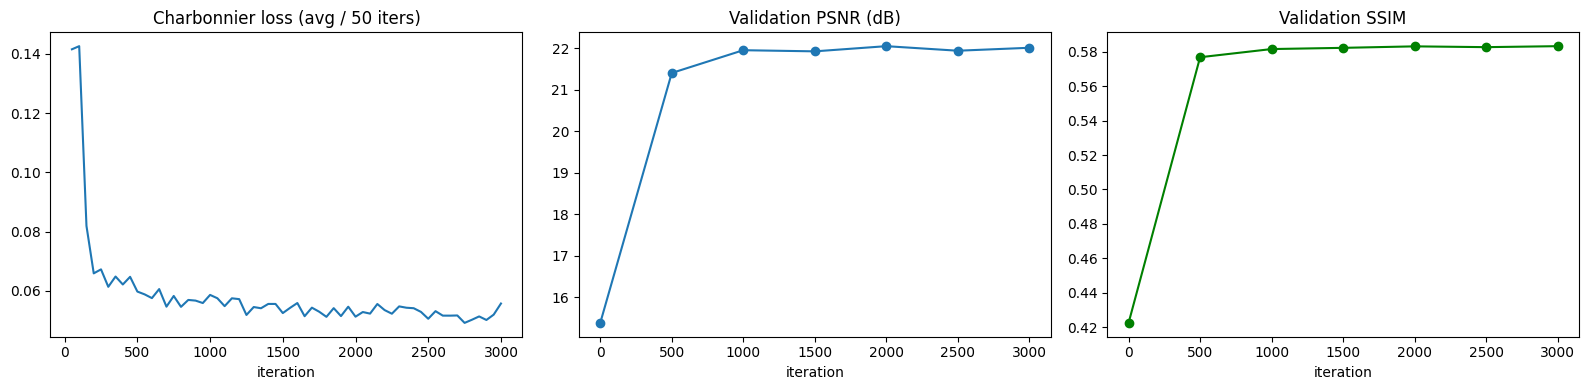

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist['iter'], hist['loss'])
ax[0].set_title('Charbonnier loss (avg / 50 iters)')
ax[0].set_xlabel('iteration')
ax[1].plot(hist['val_iter'], hist['val_psnr'], marker='o')
ax[1].set_title('Validation PSNR (dB)')
ax[1].set_xlabel('iteration')
ax[2].plot(hist['val_iter'], hist['val_ssim'], marker='o', color='green')
ax[2].set_title('Validation SSIM')
ax[2].set_xlabel('iteration')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/training_curves.png', dpi=150)
plt.show()

In [ ]:
model_ft = build_model()
model_ft.load_state_dict(torch.load(BEST, map_location='cpu'))
os.makedirs(f'{REST_DIR}/finetuned', exist_ok=True)

for tid in tqdm(split['test'], desc='Fine-tuned'):
    blur, sharp = data[tid]
    out = restore(model_ft, blur)
    p, s = img_metrics(out, sharp)
    res['Fine-tuned Restormer'][tid] = {'psnr': p, 'ssim': s}
    restored['Fine-tuned Restormer'][tid] = out.astype(np.float16)
    save_png16(out, f'{REST_DIR}/finetuned/{tid}.png')

del model_ft
torch.cuda.empty_cache()

for k in res:
    v = pd.DataFrame(res[k]).T
    print(f'{k:22s}  PSNR {v.psnr.mean():.2f} dB | SSIM {v.ssim.mean():.4f}')

Fine-tuned:   0%|          | 0/40 [00:00<?, ?it/s]

Blurred input           PSNR 15.35 dB | SSIM 0.3724
Pretrained Restormer    PSNR 15.29 dB | SSIM 0.4188
Fine-tuned Restormer    PSNR 21.98 dB | SSIM 0.5824


In [ ]:
import easyocr
reader = easyocr.Reader(['en'], gpu=True)

def to_u8(img):
    return (np.clip(img.astype(np.float32), 0, 1) * 255).round().astype(np.uint8)

def ocr_text(img):
    out = reader.readtext(to_u8(img), detail=1, paragraph=False)
    if len(out) == 0:
        return ''
    items = []
    for box, txt, conf in out:
        ys = [pt[1] for pt in box]
        xs = [pt[0] for pt in box]
        items.append((np.mean(ys), min(xs), max(ys) - min(ys), txt))
    items.sort(key=lambda t: t[0])
    lines = []
    for itm in items:
        if len(lines) > 0 and abs(itm[0] - lines[-1][0][0]) < 0.5 * itm[2]:
            lines[-1].append(itm)
        else:
            lines.append([itm])
    text_lines = []
    for ln in lines:
        ln.sort(key=lambda t: t[1])
        text_lines.append(' '.join(t[3] for t in ln))
    return ' '.join(text_lines)

def clean(s):
    return ' '.join(s.split())

def char_acc(pred, gt):
    gt_c = clean(gt)
    if len(gt_c) == 0:
        return float('nan')
    d = Levenshtein.distance(clean(pred), gt_c)
    return max(0.0, 1.0 - d / len(gt_c))

def token_acc(pred, gt):
    gt_tok = clean(gt).split()
    if len(gt_tok) == 0:
        return float('nan')
    pred_tok = clean(pred).split()
    hits = 0
    for t in gt_tok:
        if t in pred_tok:
            pred_tok.remove(t)
            hits += 1
    return hits / len(gt_tok)

res['Sharp GT (upper bound)'] = {}
restored['Sharp GT (upper bound)'] = {tid: data[tid][1] for tid in split['test']}

ocr_rows = []
for method in ['Sharp GT (upper bound)', 'Blurred input', 'Pretrained Restormer', 'Fine-tuned Restormer']:
    for tid in tqdm(split['test'], desc=method):
        pred = ocr_text(restored[method][tid])
        gt = gt_text[tid]
        if tid not in res[method]:
            res[method][tid] = {}
        res[method][tid]['char_acc'] = char_acc(pred, gt)
        res[method][tid]['token_acc'] = token_acc(pred, gt)
        ocr_rows.append({'method': method, 'id': tid, 'gt': clean(gt), 'ocr': clean(pred)})

pd.DataFrame(ocr_rows).to_csv(f'{OUT}/ocr_outputs.csv', index=False)
print('OCR done')

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Sharp GT (upper bound):   0%|          | 0/40 [00:00<?, ?it/s]

Blurred input:   0%|          | 0/40 [00:00<?, ?it/s]

Pretrained Restormer:   0%|          | 0/40 [00:00<?, ?it/s]

Fine-tuned Restormer:   0%|          | 0/40 [00:00<?, ?it/s]

OCR done


In [ ]:
pair_by_id = {p['id']: p for p in pairs}
rows = []
for method, d in res.items():
    for tid, m in d.items():
        rows.append({'method': method, 'id': tid, 'font': pair_by_id[tid]['font'], **m})
df = pd.DataFrame(rows)
df.to_csv(f'{OUT}/level5_per_image.csv', index=False)

order = ['Blurred input', 'Pretrained Restormer', 'Fine-tuned Restormer', 'Sharp GT (upper bound)']
summary = df.groupby('method')[['psnr', 'ssim', 'char_acc', 'token_acc']].mean().reindex(order)
summary.to_csv(f'{OUT}/level5_summary.csv')
by_font = df.groupby(['method', 'font'])[['psnr', 'ssim', 'char_acc']].mean().reindex(order, level=0)
by_font.to_csv(f'{OUT}/level5_by_font.csv')

print('=== LEVEL 5 - TEST SET (n = %d) ===' % len(split['test']))
print(summary.round(4).to_string())
print('\n=== By font ===')
print(by_font.round(4).to_string())

ft = summary.loc['Fine-tuned Restormer']
pre = summary.loc['Pretrained Restormer']
bl = summary.loc['Blurred input']
print('\n=== Gains of fine-tuned model ===')
print(f"vs pretrained : PSNR {ft.psnr - pre.psnr:+.2f} dB | SSIM {ft.ssim - pre.ssim:+.4f} | CharAcc {100 * (ft.char_acc - pre.char_acc):+.1f} pts")
print(f"vs blurred    : PSNR {ft.psnr - bl.psnr:+.2f} dB | SSIM {ft.ssim - bl.ssim:+.4f} | CharAcc {100 * (ft.char_acc - bl.char_acc):+.1f} pts")

=== LEVEL 5 - TEST SET (n = 40) ===
                           psnr    ssim  char_acc  token_acc
method                                                      
Blurred input           15.3477  0.3724    0.0000     0.0000
Pretrained Restormer    15.2885  0.4188    0.0000     0.0000
Fine-tuned Restormer    21.9750  0.5824    0.9694     0.7500
Sharp GT (upper bound)      NaN     NaN    0.9411     0.6471

=== By font ===
                                      psnr    ssim  char_acc
method                 font                                 
Blurred input          timesR      15.5792  0.3780    0.0000
                       verdanaRef  15.1163  0.3669    0.0000
Pretrained Restormer   timesR      15.5339  0.4243    0.0000
                       verdanaRef  15.0432  0.4133    0.0000
Fine-tuned Restormer   timesR      21.7672  0.5839    0.9671
                       verdanaRef  22.1828  0.5809    0.9716
Sharp GT (upper bound) timesR          NaN     NaN    0.9215
                       verdanaRe

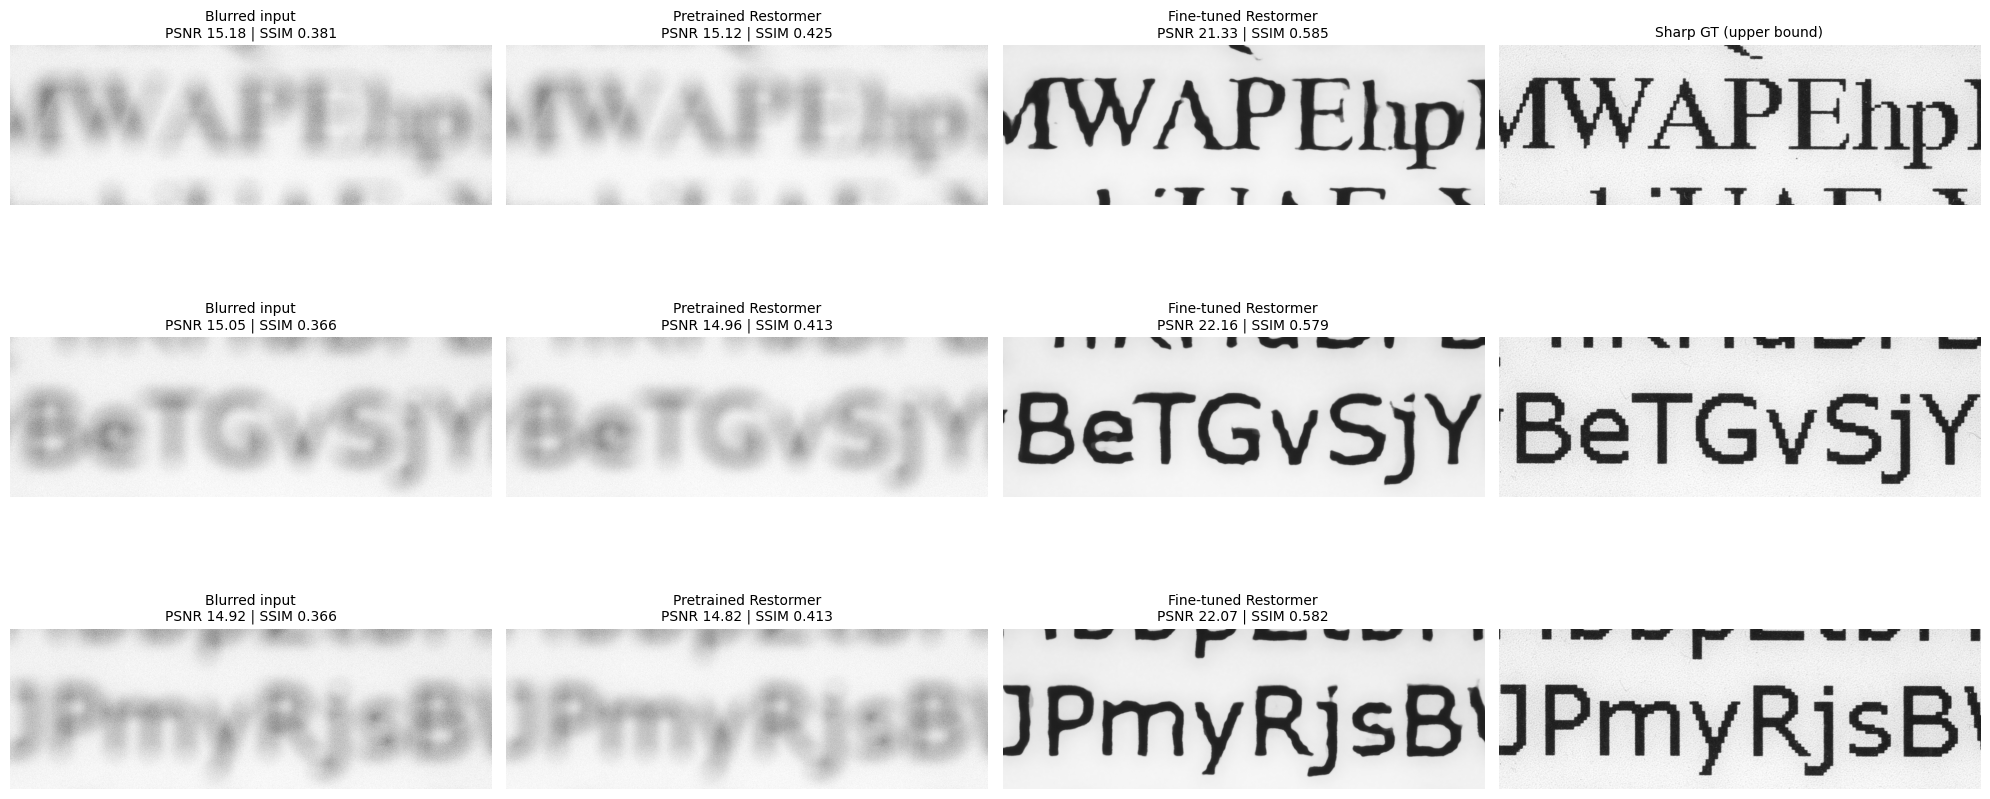

Everything saved in: /content/drive/MyDrive/FinalYearProject-Phase2/level5_results


In [ ]:
show_ids = [split['test'][0], split['test'][20], split['test'][-1]]   # mix of both fonts
cols = ['Blurred input', 'Pretrained Restormer', 'Fine-tuned Restormer', 'Sharp GT (upper bound)']

fig, axes = plt.subplots(len(show_ids), 4, figsize=(20, 3.2 * len(show_ids)))
for r, tid in enumerate(show_ids):
    H, W = data[tid][1].shape
    y0, x0 = H // 2 - 200, W // 2 - 600     # central text crop
    for c, method in enumerate(cols):
        crop = restored[method][tid][y0:y0 + 400, x0:x0 + 1200].astype(np.float32)
        axes[r, c].imshow(crop, cmap='gray', vmin=0, vmax=1)
        axes[r, c].axis('off')
        title = method
        if 'ssim' in res[method].get(tid, {}):
            title += f"\nPSNR {res[method][tid]['psnr']:.2f} | SSIM {res[method][tid]['ssim']:.3f}"
        if r == 0 or 'ssim' in res[method].get(tid, {}):
            axes[r, c].set_title(title, fontsize=10)
    axes[r, 0].set_ylabel(tid)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/level5_comparison.png', dpi=150)
plt.show()
print('Everything saved in:', OUT)

In [ ]:
import shutil, os
for d in [CKPT_DIR, f'{REST_DIR}/pretrained', f'{REST_DIR}/finetuned']:
    if os.path.exists(d):
        shutil.rmtrxee(d)
    os.makedirs(d, exist_ok=True)
for f in ['training_history.json', 'level5_per_image.csv', 'level5_summary.csv', 'level5_by_font.csv', 'ocr_outputs.csv']:
    p = f'{OUT}/{f}'
    if os.path.exists(p):
        os.remove(p)
print('Old (wrong) results deleted. split.json kept - the train/val/test split is still valid.')

Old (wrong) results deleted. split.json kept - the train/val/test split is still valid.
